In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from src.research.qcut_analyzer import QcutAnalyzer
# QcutAnalyzer.plot_qcut_analysis(df, col_a='Factor_A', col_b='Return')
%load_ext autoreload
%autoreload 2
from sdk_core import configure
from sdk_core import TwMarketData
# configure()
from src.research.rolling_model import train_and_predict_ridge_rolling

tw = TwMarketData()
# 取得還原股價
df = tw.get_security_price_adjusted("2025-12-31", "2330")

import os
import numpy as np
from tqdm import tqdm
import time
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
# 將最大顯示欄位數量設為 None（代表無上限）
pd.set_option('display.max_columns', None)

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))

import pyarrow as pa
schema = pa.schema([
    ('price', pa.decimal128(10, 4)), 
    # 其他欄位如果沒特別指定，pyarrow 會自動推斷
])

from src.research.backTest import BackTest


In [2]:

folder_path = './data'  # 資料夾路徑
files = os.listdir(folder_path)

# 過濾掉資料夾，只留下檔案
file_names = np.array([f for f in files if os.path.isfile(os.path.join(folder_path, f))])
file_names.sort()
print(file_names[-30:])

['20260723.parquet' '20260724.parquet' '20260727.parquet'
 '20260728.parquet' '20260729.parquet' '20260730.parquet'
 '20260731.parquet' '20260803.parquet' '20260804.parquet'
 '20260805.parquet' '20260806.parquet' '20260807.parquet'
 '20260810.parquet' '20260811.parquet' '20260812.parquet'
 '20260813.parquet' '20260814.parquet' '20260817.parquet'
 '20260818.parquet' '20260819.parquet' '20260820.parquet'
 '20260821.parquet' '20260824.parquet' '20260825.parquet'
 '20260826.parquet' '20260827.parquet' '20260828.parquet'
 '20260831.parquet' '20260901.parquet' '20260902.parquet']


In [3]:
data = []

# 範例：處理 100 個檔案
for f in tqdm (file_names[-230:]): 
    targetLabel = 'BidPrice1' 
    rankThres_btn = 0 
    rankThres = 150
    stock_df = pd.read_parquet( f'{folder_path}/{f}' )[lambda x : x[targetLabel] * x.BidPrice1 > 0]
    try : 
        stock_df['ToRef'] = ((stock_df['BidPrice1'] - stock_df.RefPrice) / stock_df.RefPrice ).round(6)
        stock_df['ToOpen'] = ((stock_df['BidPrice1'] - stock_df.Open) / stock_df.Open ).round(6)
        # stock_df['TakerSell_CloseBP'] = ((stock_df[targetLabel]- stock_df.Close) / stock_df[targetLabel] * 10000)
        # stock_df.loc[ stock_df.FutureHigh > stock_df.RefPrice*1.09 , 'TakerSell_CloseBP'] = ((stock_df[targetLabel] - stock_df.FutureHigh) / stock_df[targetLabel] * 10000)
        stock_df['TakerSell_CloseBP'] = ((stock_df[targetLabel]- stock_df.Close) / stock_df[targetLabel] * 10000)
        stock_df.loc[ stock_df.FutureHigh > stock_df.RefPrice*1.08 , 'TakerSell_CloseBP'] = ((stock_df[targetLabel] - stock_df.RefPrice*1.08 - stock_df.TickSize*2) / stock_df[targetLabel] * 10000)
        PriceCondition = (stock_df.ToRef > -0.015) & (stock_df.ToRef < 0.05)
        # seqCondition = (stock_df.BidPrice1.diff()!= 0)
        AmountCondition = (stock_df.day_amount_rank <= rankThres) | (stock_df.AmountRank_canDayTrade <= rankThres) 
        # AmountCondition2 = (stock_df.day_amount_rank > rankThres_btn) & (stock_df.AmountRank > rankThres_btn)
        # preMarketCondition = (stock_df.day_amount_rank <= 50.1) | (stock_df.AmountRank <= 50.1)
        temp = stock_df[ PriceCondition & AmountCondition].reset_index(drop=True)
        temp['Date'] = f.split('.')[0]
        data.append(temp)
    except : 
        print('Filled in ', f)
        continue
        # break       
    # if f.split('.')[0] == '20260309':
    #     break

100%|██████████| 230/230 [00:56<00:00,  4.04it/s]


In [4]:
import gc

if 'signal_df' in locals():
    del signal_df
    gc.collect()

signal_df = pd.concat(data, ignore_index=True, copy=False)

priceReturnColumn = ["TransTime", "QuoteCode", "ChannelSeq","TotalFillLots","BidPrice1","BidLots1", "AskPrice1","AskLots1", "RecordHigh","FutureHigh", "RefPrice" , "Close" , "Open", "Spread", "TakerSell_CloseBP" ]
signal_df[priceReturnColumn + ['ToRef','FillLots_atLow','day_amount_rank', 'AmountRank', 'TimeSlot','TransTime_tb']].head(10)


/tmp/ipykernel_1248935/2134462285.py:7: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  signal_df = pd.concat(data, ignore_index=True, copy=False)


,TransTime,QuoteCode,ChannelSeq,TotalFillLots,BidPrice1,BidLots1,AskPrice1,AskLots1,RecordHigh,FutureHigh,RefPrice,Close,Open,Spread,TakerSell_CloseBP,ToRef,FillLots_atLow,day_amount_rank,AmountRank,TimeSlot,TransTime_tb
0,2025-09-19 11:42:52.906419,1101,7787284,26867,22.40,446,22.50,455,22.7,23.35,22.2,23.35,22.2,2.0,-424.107143,0.009009,-88,208.0,130.0,11:40:00,2025-09-19 11:39:56.375177
1,2025-09-19 11:45:12.910794,1101,7843829,27087,22.40,414,22.50,796,22.7,23.35,22.2,23.35,22.2,2.0,-424.107143,0.009009,-82,208.0,129.0,11:45:00,2025-09-19 11:44:59.359725
2,2025-09-19 11:45:13.064124,1101,7843891,27087,22.45,2,22.50,796,22.7,23.35,22.2,23.35,22.2,1.0,-400.890869,0.011261,-82,208.0,129.0,11:45:00,2025-09-19 11:44:59.359725
3,2025-09-19 11:45:14.111948,1101,7844296,27087,22.40,404,22.50,796,22.7,23.35,22.2,23.35,22.2,2.0,-424.107143,0.009009,-82,208.0,129.0,11:45:00,2025-09-19 11:44:59.359725
4,2025-09-19 11:45:35.940204,1101,7851668,27121,22.40,440,22.50,799,22.7,23.35,22.2,23.35,22.2,2.0,-424.107143,0.009009,-48,208.0,129.0,11:45:00,2025-09-19 11:44:59.359725
5,2025-09-19 12:12:37.233665,1101,8639359,29522,22.40,2,22.45,253,22.7,23.35,22.2,23.35,22.2,1.0,-424.107143,0.009009,-1867,208.0,128.0,12:10:00,2025-09-19 12:09:57.977249
6,2025-09-19 12:12:37.468750,1101,8639474,29585,22.40,4,22.45,218,22.7,23.35,22.2,23.35,22.2,1.0,-424.107143,0.009009,-1840,208.0,128.0,12:10:00,2025-09-19 12:09:57.977249
7,2025-09-19 12:12:37.502828,1101,8639497,29645,22.40,18,22.45,218,22.7,23.35,22.2,23.35,22.2,1.0,-424.107143,0.009009,-1796,208.0,128.0,12:10:00,2025-09-19 12:09:57.977249
8,2025-09-19 12:12:37.519220,1101,8639501,29649,22.35,808,22.45,214,22.7,23.35,22.2,23.35,22.2,2.0,-447.427293,0.006757,-1792,208.0,128.0,12:10:00,2025-09-19 12:09:57.977249
9,2025-09-19 12:12:37.527057,1101,8639509,29649,22.40,6,22.45,214,22.7,23.35,22.2,23.35,22.2,1.0,-424.107143,0.009009,-1792,208.0,128.0,12:10:00,2025-09-19 12:09:57.977249


In [5]:
signal_df['residual_TakerSell_CloseBP'] = (
    signal_df.TakerSell_CloseBP
    + signal_df.txf_beta_60d * signal_df.txf_to_1330_bp        # BP，單位已對齊
) / (signal_df.txf_residual_vol_to_1330 * 1e4)      

In [6]:
signal_df['ToRef_bucket'] = (signal_df.ToRef * 100 / 2 ).round()


In [7]:
signal_df = signal_df[ (signal_df.TransTime.dt.time < datetime.time(12, 30, 0)) & (signal_df.TransTime.dt.time > datetime.time(9, 0, 30)) & (signal_df.TrialMatch == 0) ].reset_index(drop=True)
signal_df = signal_df[  (signal_df.TakerSell_CloseBP.abs() < 10000) ].sort_values(['Date', 'QuoteCode', 'TransTime']).reset_index(drop=True)
signal_df['midEdge_300sBP'] = signal_df['midEdge_300sBP']*-1

<Axes: xlabel='Date'>

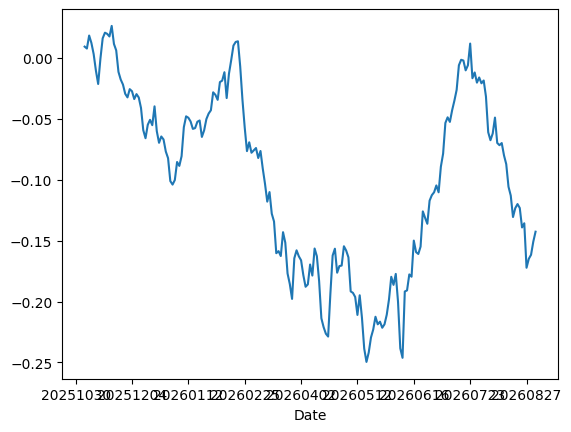

In [8]:
signal_df[:].groupby(['Date','QuoteCode']).residual_TakerSell_CloseBP.mean().reset_index().groupby(['Date']).residual_TakerSell_CloseBP.mean().rolling(30).mean().plot()

In [9]:
signal_df['TakerSell_CloseBP_net'] = signal_df.residual_TakerSell_CloseBP.copy() - signal_df.groupby(['Date','QuoteCode']).residual_TakerSell_CloseBP.transform('mean') #- (signal_df.FutureHigh > signal_df.RefPrice *1.08) * 20#.clip(lower=-130, upper=130)
signal_df['TakerSell_CloseBP_netM'] = signal_df.residual_TakerSell_CloseBP - signal_df.groupby(['Date']).residual_TakerSell_CloseBP.transform('mean') #.clip(lower=-130, upper=130)
# signal_df['TakerSell_CloseBP_net'] = signal_df.TakerSell_CloseBP - signal_df.groupby(['Date','QuoteCode']).TakerSell_CloseBP.transform('mean')#.clip(lower=-130, upper=130)
# signal_df['TakerSell_CloseBP_net'] = signal_df.TakerSell_CloseBP - signal_df.groupby(['Date']).TakerSell_CloseBP.transform('mean')

<Axes: xlabel='Date'>

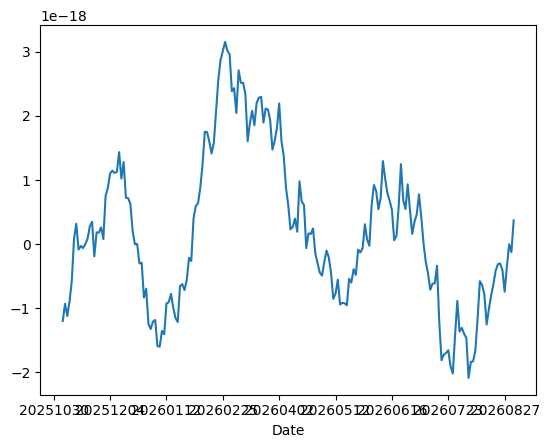

In [10]:
signal_df[:].groupby(['Date','QuoteCode']).TakerSell_CloseBP_net.mean().reset_index().groupby(['Date']).TakerSell_CloseBP_net.mean().rolling(30).mean().plot()

In [11]:
# abnormal 機制已整個移除（2026-08-27 決定，與 src/strategy/negFill/modelUpdate.py 一致）：
# 不再讀 abnormal_dates.json、不設 isAbnormalDate。所有交易日都進 normal 模型訓練；門檻也不分組。
# 注意：只要 signal_df 有 isAbnormalDate 欄，train_and_predict_ridge_rolling 就會把那些日子踢出訓練集，所以整欄不能存在。
signal_df = signal_df.drop(columns=['isAbnormalDate'], errors='ignore')

In [12]:
signal_df['B2_Last'] = signal_df.BidLots2 / signal_df.avg_bidLots1
signal_df['A2_Last'] = signal_df.AskLots2 / signal_df.avg_askLots1

signal_df['B1_B12'] = signal_df.BidLots1 / (signal_df.BidLots1+signal_df.BidLots2)
signal_df['A1_A12'] = signal_df.AskLots1 / (signal_df.AskLots1+signal_df.AskLots2)
signal_df['B45_AB45'] = (signal_df.BidLots4 + signal_df.BidLots5 ) / (signal_df.AskLots4 + signal_df.AskLots5 + signal_df.BidLots4 + signal_df.BidLots5 )

signal_df['Total_Last'] = signal_df.TotalFillLots / signal_df.last_fillLots
signal_df['TickBP'] = signal_df.TickSize / signal_df.BidPrice1 * 10000
signal_df['LOB_BidVelocity_30_re'] = signal_df.LOB_BidVelocity_30.abs() / signal_df.avg_bidLots1
signal_df['LOB_AskVelocity_30_re'] = signal_df.LOB_AskVelocity_30.abs() / signal_df.avg_askLots1

signal_df['FillLots_atLow_re'] = signal_df.FillLots_atLow / (signal_df.avg_bidLots1 + signal_df.avg_askLots1)
signal_df['FillLots_atHigh_re'] = signal_df.FillLots_atHigh / (signal_df.avg_bidLots1 + signal_df.avg_askLots1)

signal_df['L1_SellBiggestLots_30_re'] = signal_df.L1_SellBiggestLots_30.abs() / signal_df.big_sell_lots
signal_df['L1_BuyBiggestLots_30_re'] = signal_df.L1_BuyBiggestLots_30.abs() / signal_df.big_buy_lots

signal_df['MD_ElaspeTime_30_re'] = (signal_df.MD_ElaspeTime_30+1).apply(np.log)
signal_df['MD_L1Rate_30_re'] = signal_df.MD_L1Rate_30

signal_df['IA_BuyImpact_30_re'] = (signal_df.IA_BuyImpact_30.abs()+1).apply(np.log)
signal_df['IA_SellImpact_30_re'] = (signal_df.IA_SellImpact_30.abs()+1).apply(np.log)
signal_df['LOB_NetPressure_30_re'] = (signal_df.LOB_NetPressure_30.abs()+1).apply(np.log)
signal_df['QL_Asymmetry_re'] = (signal_df.QL_Asymmetry.abs()+1).apply(np.log)


/tmp/ipykernel_1248935/489644927.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  signal_df['L1_BuyBiggestLots_30_re'] = signal_df.L1_BuyBiggestLots_30.abs() / signal_df.big_buy_lots
/tmp/ipykernel_1248935/489644927.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  signal_df['MD_ElaspeTime_30_re'] = (signal_df.MD_ElaspeTime_30+1).apply(np.log)
/tmp/ipykernel_1248935/489644927.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performa

In [13]:
based_columns = ['QuoteCode', 'ChannelSeq', 'InOut', 'Overshoot', 'TotalFillLots', 'BidPrice1','BidLots1', 'BidLots5', 'AskPrice1', 'AskLots1', 'AskLots5', 'FillLots']
feature_columns = ['ToLow', 'ToHigh', 'Low_High', 'TickSize', 'TickBP', 'ToRef', 'ToOpen', 'B1_A1B1', 'B1_B1B5', 'B12_B1B5', 'A1_A1A5', 'A12_A1A5', 'Spread', 'RemainSeconds']#'B1_Last','Total_Last']
cross_columns = ['AmountRank', 'netAmountRank', 'TotalFillLotsRank', 'netTotalFillLotsRank', 'ToRefRank']
day_columns = ['dealer_hedging_netLots', 'dealer_netLots', 'foreign_dealer_netLots', 'foreign_netLots', 'investment_netLots', 'margin_netLots', 'short_netLots', 'nextday_allow_day_trade_mark', 'trading_volume_noOdd', 'big_buy_lots', 'big_buy_ToCloseBP', 'big_buy_300sBP', 'big_sell_lots', 'big_sell_ToCloseBP', 'big_sell_300sBP', 'hft_participation', 'hft_buy_ToCloseBP', 'hft_buy_300sBP', 'hft_sell_ToCloseBP', 'hft_sell_300sBP', 'day_amount_rank', 'day_lots_rank']
# # 
feature = based_columns + feature_columns + cross_columns + day_columns
label = 'TakerSell_CloseBP_net'
# feature_columns = ['ToLow', 'ToHigh', 'Low_High',  'RemainSeconds',  'ToOpen', 'ToRef',
#   'B1_A1B1', 'B1_B1B5', 'A1_A1A5', 'B2_Last', 'A2_Last', 'B45_AB45','B1_B12','A1_A12', 'QL_BidHHI', 'QL_AskHHI'] + signal_df.columns[ (signal_df.columns.str.contains('_re')) & ~(signal_df.columns.str.contains('2330')) & ~(signal_df.columns.str.startswith('txf_')) ].tolist() + ['txf_residual_vol_to_1330', 'txf_residual_vol_0900_1330_60d']
# txf_to_1330_return 是事件→13:30 的期貨「未來」報酬，_re regex 會掃到它，絕不可進特徵
feature_columns = ['ToLow', 'ToHigh', 'Low_High', 'ToRef', 'ToOpen', 'B1_A1B1','B1_B1B5', 'A1_A1A5', 'B45_AB45','B1_B12','A1_A12', 'RemainSeconds', 'MD_ElaspeTime_30_re','MD_L1Rate_30']#, 'txf_residual_vol_to_1330', 'txf_residual_vol_0900_1330_60d'] # + signal_df.columns[ (signal_df.columns.str.contains('_re')) & ~(signal_df.columns.str.contains('2330')) ].tolist()
# day_columns = ['foreign_netLots', 'investment_netLots','margin_netLots','turnover_rate','hft_strick_makerSpreadBP','hft_strick_participation','hft_participation','big_sell_ToCloseBP']

In [14]:
for c in feature_columns : 
    signal_df[c] = signal_df[c].round(6)
signal_df ['OTC'] = signal_df ['OTC'] * 1

🔍 目前預測目標: TakerSell_CloseBP_net | Rolling Training 視窗: 60 天
🔄 為了 O(1) NumPy 加速，強制將資料依照 Date, QuoteCode, TransTime 進行排序...
📊 資料總筆數: 6595784
🔄 填補特徵遺失值 (依據前一交易日之中位數)...
----------------------------------------
🚀 總輸入 current_X (共 14 個)
   - Tick Baseline: 14 個
   - Day Features:  0 個
   - Forced Masks:  0 個
----------------------------------------
🔄 計算 Lot Mask 與準備 NumPy 陣列
🔬 Phase 1: 預先計算 Feature Screening (worker: 16)...


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done   9 tasks      | elapsed:    0.3s
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.5s
[Parallel(n_jobs=16)]: Done  29 tasks      | elapsed:    1.0s
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    1.6s
[Parallel(n_jobs=16)]: Done  53 tasks      | elapsed:    2.4s
[Parallel(n_jobs=16)]: Done  66 tasks      | elapsed:    3.5s
[Parallel(n_jobs=16)]: Done  81 tasks      | elapsed:    4.8s
[Parallel(n_jobs=16)]: Done  96 tasks      | elapsed:    6.2s
[Parallel(n_jobs=16)]: Done 113 tasks      | elapsed:    8.1s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    9.9s
[Parallel(n_jobs=16)]: Done 149 tasks      | elapsed:   12.4s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:   14.9s
[Parallel(n_jobs=16)]: Done 189 tasks      | elapsed:   17.7s
[Parallel(n_jobs=16)]: Done 223 out of 230 | elapsed:   22.6s remaining:    0.7s
[Parallel(n_jobs=16)]: Done 230

✅ Phase 1 完成！
▶️ Phase 2: Rolling Update (Core: -1)...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:    1.7s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    3.0s
[Parallel(n_jobs=-1)]: Done  49 tasks      | elapsed:    5.3s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:    6.9s
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:    9.7s
[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:   12.0s
[Parallel(n_jobs=-1)]: Done 117 tasks      | elapsed:   15.3s
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:   18.4s
[Parallel(n_jobs=-1)]: Done 157 tasks      | elapsed:   22.5s
[Parallel(n_jobs=-1)]: Done 191 out of 230 | elapsed:   30.7s remaining:    6.3s
[Parallel(n_jobs=-1)]: Done 215 out of 230 | elapsed:   34.5s remaining:    2.4s
[Parallel(n_jobs=-1)]: Done 230 out of 230 | elapsed:   35.1s finished


✅ 平行 Rolling 更新預測完成！
  Rolling Model Dashboard — NORMAL Model
  交易日數: 229  |  特徵數: 14
  Feature Screening: OFF (所有天都使用全部特徵)

📊 [1/2] Standardized Coefficient Importance


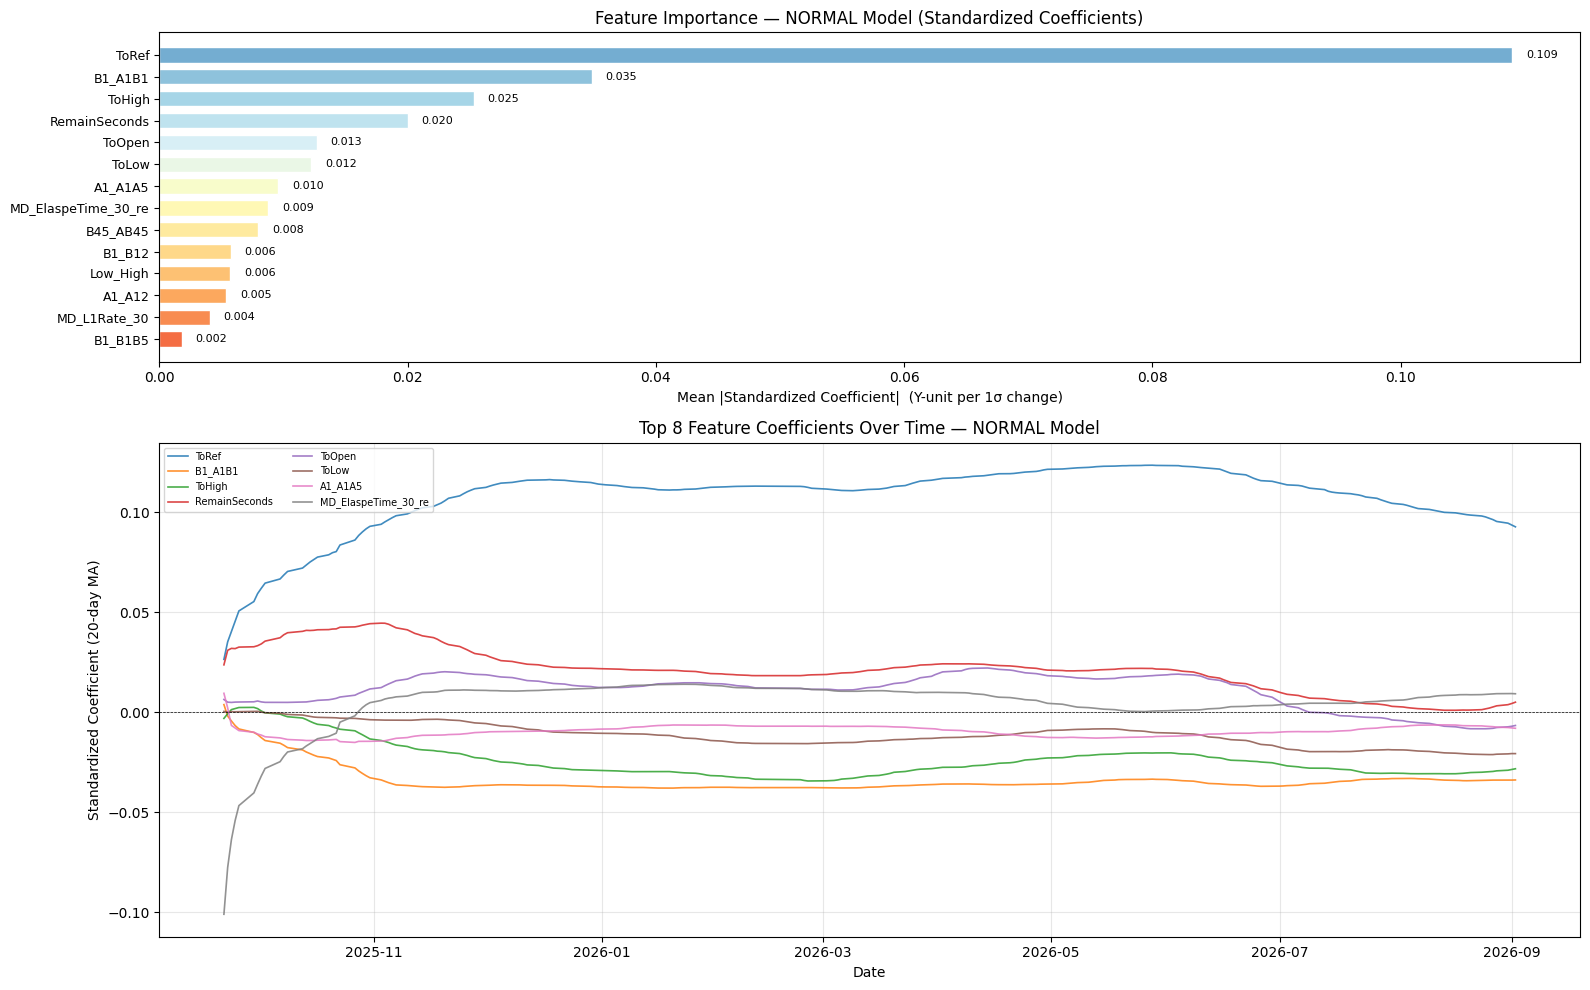


📊 [2/2] Coefficient Stability


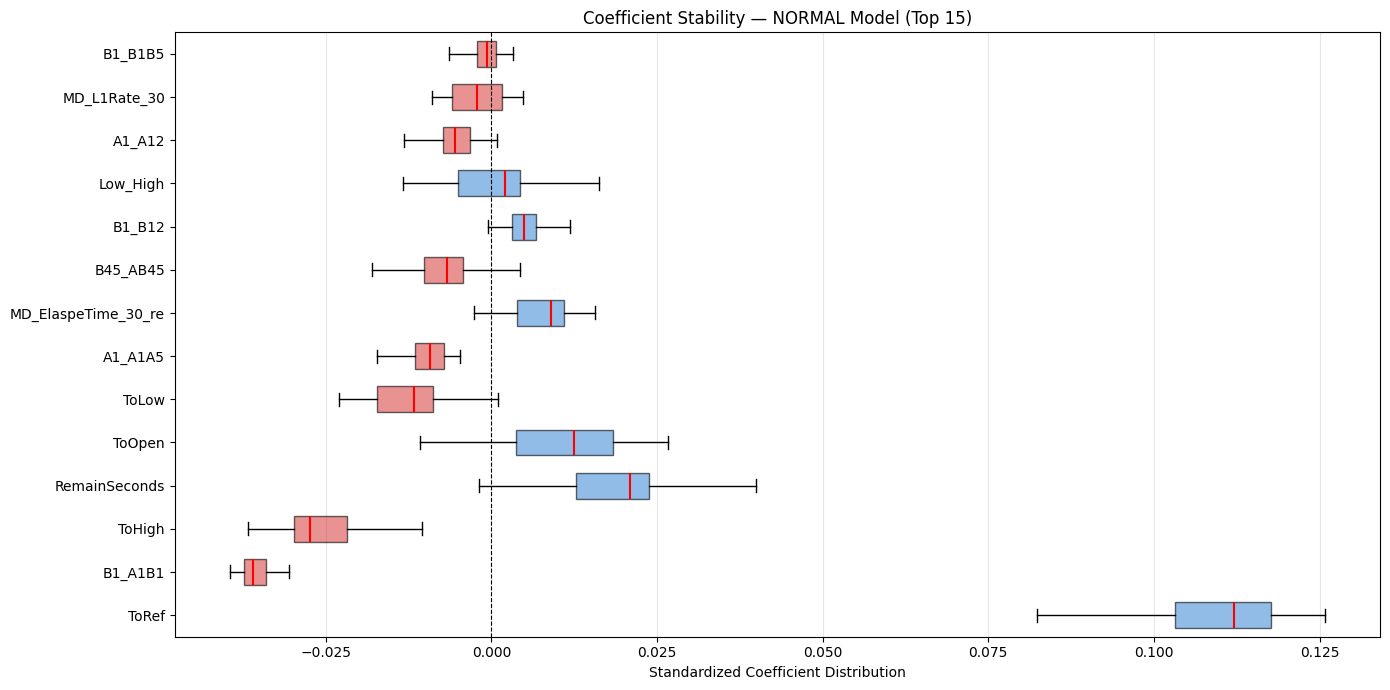

🔍 目前預測目標: TakerSell_CloseBP_netM | Rolling Training 視窗: 20 天
🔄 為了 O(1) NumPy 加速，強制將資料依照 Date, QuoteCode, TransTime 進行排序...
📊 資料總筆數: 6589502
🔄 填補特徵遺失值 (依據前一交易日之中位數)...
----------------------------------------
🚀 總輸入 current_X (共 14 個)
   - Tick Baseline: 14 個
   - Day Features:  0 個
   - Forced Masks:  0 個
----------------------------------------
🔄 計算 Lot Mask 與準備 NumPy 陣列
🔬 Phase 1: 預先計算 Feature Screening (worker: 16)...


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done   9 tasks      | elapsed:    0.3s
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.4s
[Parallel(n_jobs=16)]: Done  29 tasks      | elapsed:    0.8s
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    1.2s
[Parallel(n_jobs=16)]: Done  53 tasks      | elapsed:    1.5s
[Parallel(n_jobs=16)]: Done  66 tasks      | elapsed:    1.9s
[Parallel(n_jobs=16)]: Done  81 tasks      | elapsed:    2.4s
[Parallel(n_jobs=16)]: Done  96 tasks      | elapsed:    2.9s
[Parallel(n_jobs=16)]: Done 113 tasks      | elapsed:    3.4s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    4.0s
[Parallel(n_jobs=16)]: Done 149 tasks      | elapsed:    4.7s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    5.4s
[Parallel(n_jobs=16)]: Done 189 tasks      | elapsed:    6.3s
[Parallel(n_jobs=16)]: Done 223 out of 230 | elapsed:    7.6s remaining:    0.2s
[Parallel(n_jobs=16)]: Done 230

✅ Phase 1 完成！
▶️ Phase 2: Rolling Update (Core: -1)...


[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:    1.5s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done  49 tasks      | elapsed:    3.2s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:    4.1s
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:    5.6s
[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:    6.4s
[Parallel(n_jobs=-1)]: Done 117 tasks      | elapsed:    8.1s
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:    9.4s
[Parallel(n_jobs=-1)]: Done 157 tasks      | elapsed:   11.3s
[Parallel(n_jobs=-1)]: Done 191 out of 230 | elapsed:   14.1s remaining:    2.9s
[Parallel(n_jobs=-1)]: Done 215 out of 230 | elapsed:   15.2s remaining:    1.1s
[Parallel(n_jobs=-1)]: Done 230 out of 230 | elapsed:   15.6s finished


✅ 平行 Rolling 更新預測完成！
  Rolling Model Dashboard — NORMAL Model
  交易日數: 229  |  特徵數: 14
  Feature Screening: OFF (所有天都使用全部特徵)

📊 [1/2] Standardized Coefficient Importance


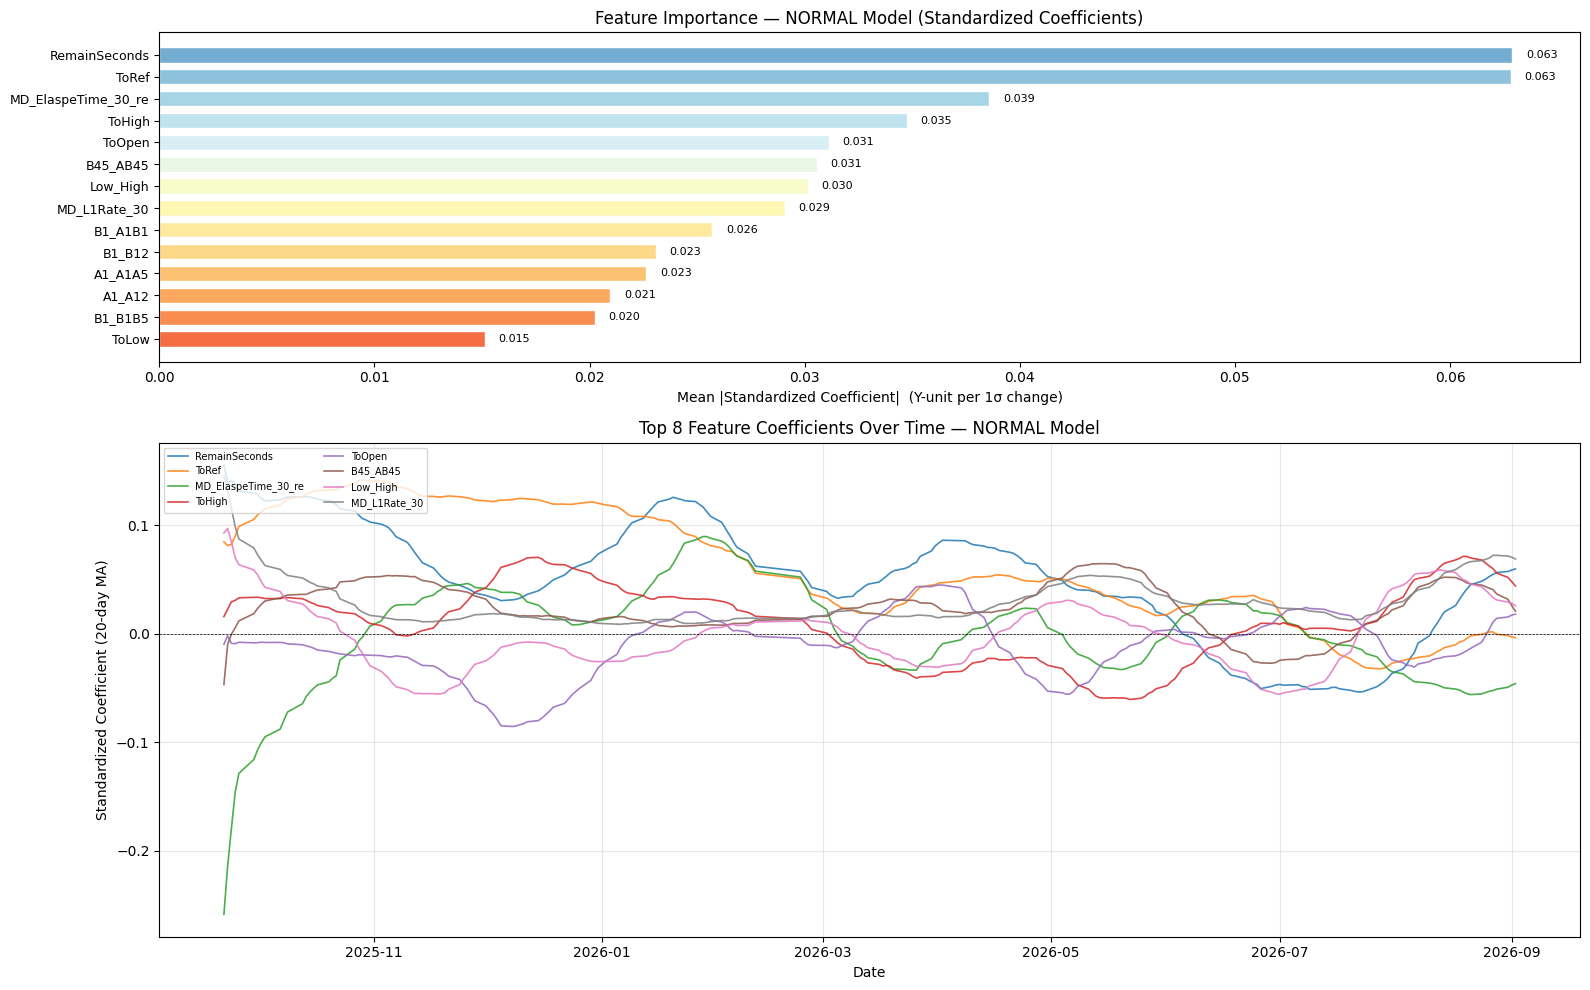


📊 [2/2] Coefficient Stability


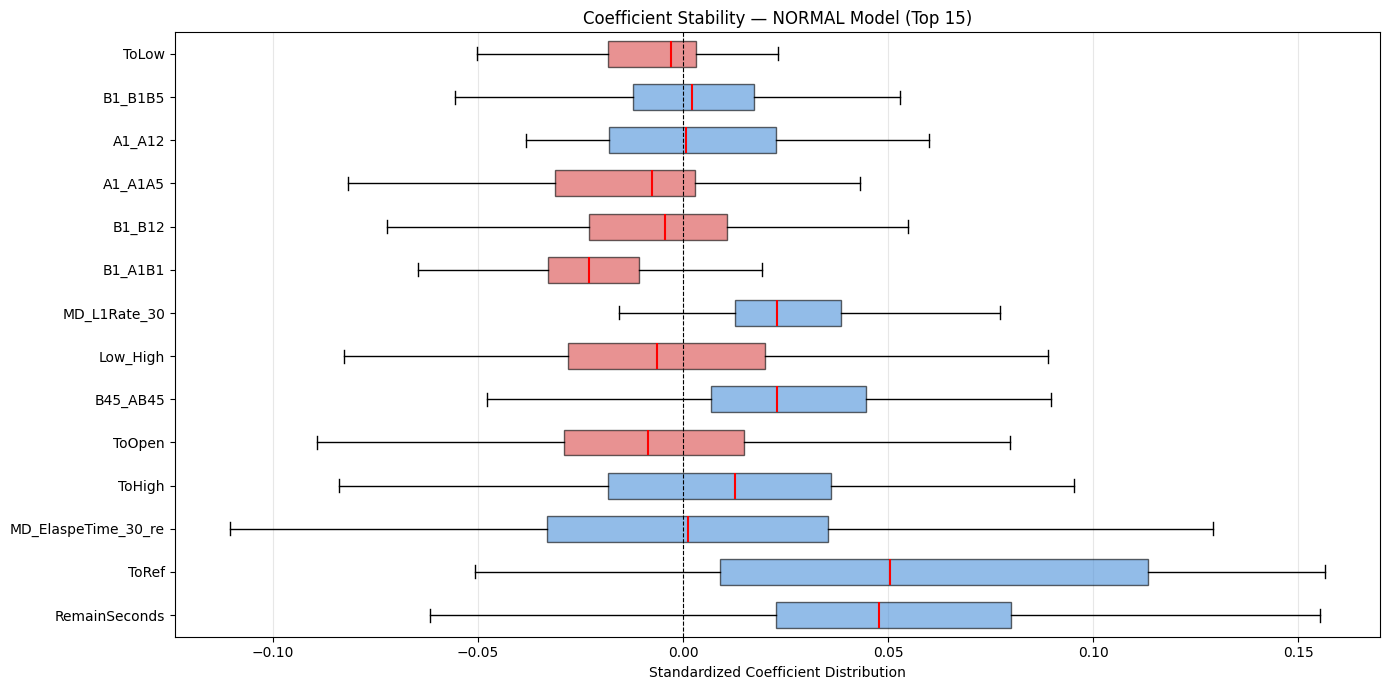

In [15]:
day_columns = []
from src.research.timeSeries.model_analysis import plot_model_dashboard

# result = train_and_predict_ridge_rolling(signal_df[:], feature_columns , label,  n_training_days=20,  day_features= day_columns, feature_screening=True, alpha=0.1 , max_position_per_stock = 500)
result = train_and_predict_ridge_rolling(signal_df[:], feature_columns , label,  n_training_days=60,  day_features= day_columns, feature_screening=True, alpha=10 , max_position_per_stock = 500)
screening_log = result['screening_log']   # {日期: [被選中的特徵名]}
coeff_log = result['coeff_log']           # {日期: {normal_coeff, normal_std_coeff, ...}}day_features= day_columns, day_features= day_columns,
signal_df = result['df']           # 原本的 DataFrameㄌ
plot_model_dashboard(result, model_type='normal')

# day_columns = ['foreign_netLots', 'investment_netLots','margin_netLots','turnover_rate','hft_strick_makerSpreadBP','hft_strick_participation','hft_participation','big_sell_ToCloseBP']
result = train_and_predict_ridge_rolling(signal_df[:], feature_columns , label+'M', n_training_days=20,  day_features= day_columns, feature_screening=True, alpha=10 , max_position_per_stock = 500)
screening_log = result['screening_log']   # {日期: [被選中的特徵名]}
coeff_log2 = result['coeff_log']           # {日期: {normal_coeff, normal_std_coeff, ...}}
signal_df = result['df']
plot_model_dashboard(result, model_type='normal')


In [16]:
coeff_log

{'2025-09-22': {'selected_features': ['ToLow',
   'ToHigh',
   'Low_High',
   'ToRef',
   'ToOpen',
   'B1_A1B1',
   'B1_B1B5',
   'A1_A1A5',
   'B45_AB45',
   'B1_B12',
   'A1_A12',
   'RemainSeconds',
   'MD_ElaspeTime_30_re',
   'MD_L1Rate_30'],
  'normal_coeff': {'ToLow': 0.08645385503768921,
   'ToHigh': -0.17758436501026154,
   'Low_High': 0.12979044020175934,
   'ToRef': 1.4027131795883179,
   'ToOpen': 0.43527868390083313,
   'B1_A1B1': 0.01255017053335905,
   'B1_B1B5': -0.04380437359213829,
   'A1_A1A5': 0.07040806114673615,
   'B45_AB45': 0.19049181044101715,
   'B1_B12': -0.10030970722436905,
   'A1_A12': -0.10125856101512909,
   'RemainSeconds': 1.1318028555251658e-05,
   'MD_ElaspeTime_30_re': -0.09734102338552475,
   'MD_L1Rate_30': 0.3408533036708832},
  'normal_std_coeff': {'ToLow': 0.0004462702781893313,
   'ToHigh': -0.0030292721930891275,
   'Low_High': 0.0318957157433033,
   'ToRef': 0.026466529816389084,
   'ToOpen': 0.006411457434296608,
   'B1_A1B1': 0.003867741

In [17]:
coeff_log2

{'2025-09-22': {'selected_features': ['ToLow',
   'ToHigh',
   'Low_High',
   'ToRef',
   'ToOpen',
   'B1_A1B1',
   'B1_B1B5',
   'A1_A1A5',
   'B45_AB45',
   'B1_B12',
   'A1_A12',
   'RemainSeconds',
   'MD_ElaspeTime_30_re',
   'MD_L1Rate_30'],
  'normal_coeff': {'ToLow': 0.5362367033958435,
   'ToHigh': 0.9242166876792908,
   'Low_High': 0.37815195322036743,
   'ToRef': 4.483511924743652,
   'ToOpen': -0.6580525636672974,
   'B1_A1B1': 0.11624708026647568,
   'B1_B1B5': -0.8772825598716736,
   'A1_A1A5': 0.5973119735717773,
   'B45_AB45': -0.2418394386768341,
   'B1_B12': 0.21615813672542572,
   'A1_A12': -0.529097855091095,
   'RemainSeconds': 7.404738425975665e-05,
   'MD_ElaspeTime_30_re': -0.2494390308856964,
   'MD_L1Rate_30': 1.3377920389175415},
  'normal_std_coeff': {'ToLow': 0.0027680257335305214,
   'ToHigh': 0.015765486285090446,
   'Low_High': 0.09293001145124435,
   'ToRef': 0.08459534496068954,
   'ToOpen': -0.009692816063761711,
   'B1_A1B1': 0.03582530468702316,
  

# z 單位的預測換回 BP 是「乘」vol（label 當初除以 vol），不是除
signal_df['TakerSell_CloseBP_netM_pred'] = signal_df['TakerSell_CloseBP_netM_pred'] * (signal_df.txf_residual_vol_to_1330 * 1e4)
signal_df['TakerSell_CloseBP_net_pred'] = signal_df['TakerSell_CloseBP_net_pred'] * (signal_df.txf_residual_vol_to_1330 * 1e4)

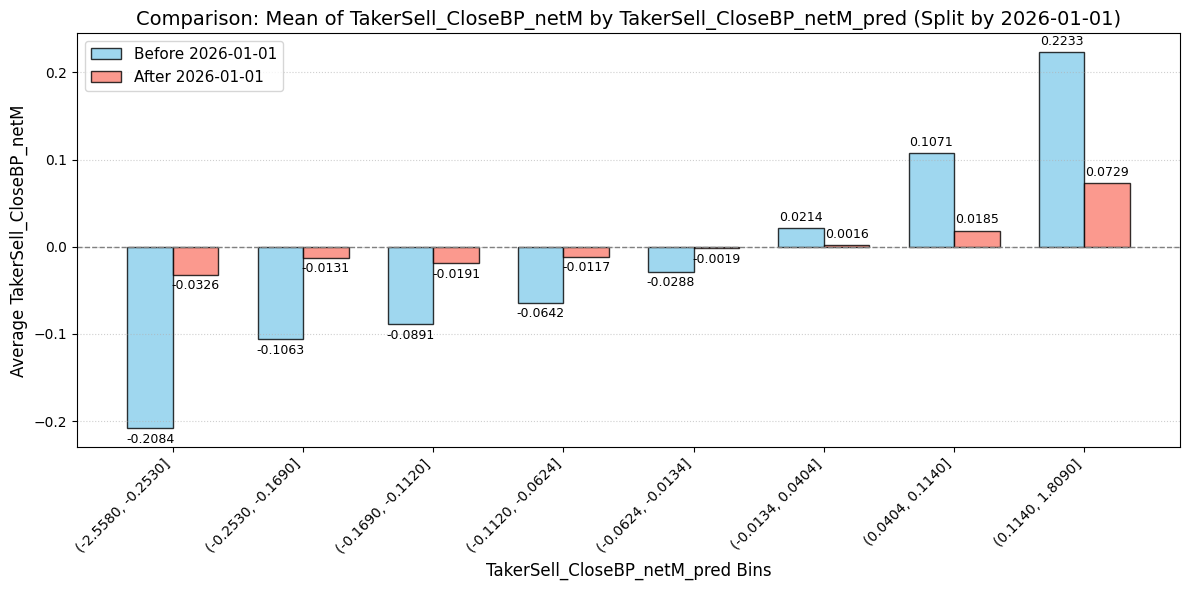

In [18]:
# 評估要對「對應 label」：pooled raw qcut 會把市場成分排進 bin（2026 反轉的來源）
QcutAnalyzer.plot_qcut_analysis(signal_df, 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP_netM', date_col='Date', split_date='2026-01-01',  q= 8)
# 對照用（含市場成分）：
# QcutAnalyzer.plot_qcut_analysis(signal_df, 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01',  q= 8)

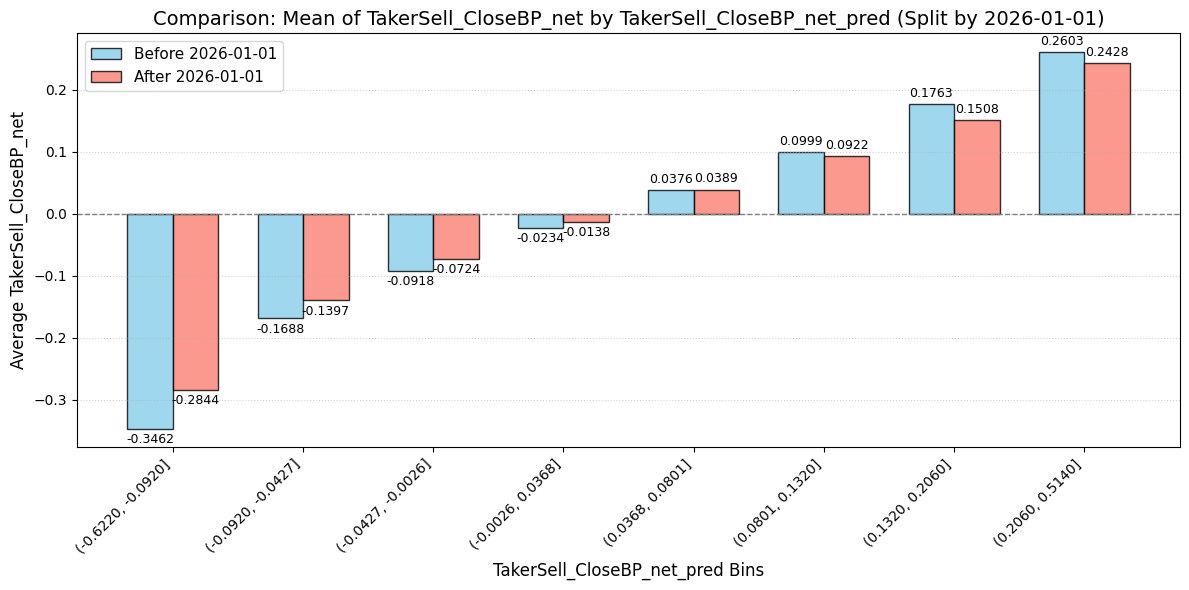

In [19]:
QcutAnalyzer.plot_qcut_analysis(signal_df, 'TakerSell_CloseBP_net_pred', 'TakerSell_CloseBP_net', date_col='Date', split_date='2026-01-01',  q= 8)
# 對照用（含市場成分）：
# QcutAnalyzer.plot_qcut_analysis(signal_df, 'TakerSell_CloseBP_net_pred', 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01',  q= 8)

In [20]:
# 每月 per-day Spearman IC：模型排序力的乾淨讀數（不受市場成分/跨日組成影響）
def _daily_ic(df, pred, label):
    return df.groupby('Date').apply(lambda p: p[pred].corr(p[label], method='spearman'))

_ic = pd.DataFrame({
    'net|net':   _daily_ic(signal_df, 'TakerSell_CloseBP_net_pred',  'TakerSell_CloseBP_net'),
    'net|raw':   _daily_ic(signal_df, 'TakerSell_CloseBP_net_pred',  'TakerSell_CloseBP'),
    'netM|netM': _daily_ic(signal_df, 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP_netM'),
    'netM|raw':  _daily_ic(signal_df, 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP'),
})
_ic.groupby(pd.to_datetime(_ic.index).strftime('%Y%m')).mean().round(4)

,net|net,net|raw,netM|netM,netM|raw
Date,,,,
202509,0.3963,0.2820,0.2081,0.2571
202510,0.5371,0.2264,0.2268,0.2407
202511,0.5399,0.2431,0.2235,0.2293
202512,0.5515,0.2131,0.1990,0.1867
202601,0.5656,0.0564,0.0491,0.0541
202602,0.5156,-0.0006,0.0413,0.0003
202603,0.5316,0.0709,0.0560,0.0888
202604,0.5300,0.0642,0.0207,0.0230
202605,0.4870,0.0186,-0.0110,0.0085


from matplotlib.pyplot import contour
from os import execve
for c in signal_df.columns :
    try :
        QcutAnalyzer.plot_qcut_analysis(signal_df_model[(signal_df_model.OTC !=1) ], c , 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01', q=8)
    except : 
        continue

In [21]:
import numpy as np
import pandas as pd


def prior_day_quantile(df, col, q=0.9, n_days=3, date_col="Date",
                       min_days=1, group=None):
    """每個交易日的門檻 = 前 n_days 個交易日該欄位的分位數（不含當日）。

    df       : DataFrame
    col      : 要取分位數的欄位（例如模型預測值）
    q        : 分位數，0.9 = 前 10%
    n_days   : 往前看幾個交易日
    min_days : 可用天數不足時回傳 NaN（該日不出訊號）
    group    : 選填，分組欄名（例如 'isAbnormalDate'），各組各自算門檻

    回傳與 df 對齊的 Series。當日資料完全不參與自己的門檻。
    """
    if group is not None:
        out = pd.Series(np.nan, index=df.index)
        for g, part in df.groupby(group, observed=True):
            out.loc[part.index] = prior_day_quantile(
                part, col, q=q, n_days=n_days, date_col=date_col,
                min_days=min_days)
        return out

    vals = (df.dropna(subset=[col])
              .groupby(date_col, observed=True)[col]
              .apply(lambda s: s.to_numpy()))
    dates = np.sort(vals.index.to_numpy())

    thr = {}
    for i, d in enumerate(dates):
        window = dates[max(0, i - n_days):i]          # 嚴格小於 d
        if len(window) < min_days:
            continue
        pool = np.concatenate([vals[w] for w in window])
        if pool.size:
            thr[d] = np.quantile(pool, q)
    return df[date_col].map(thr)


In [22]:
# 門檻於開盤前即全部固定：前 3 個交易日 pred 在同一 (時段×ToRef) 16-cell 內的分位數。
# 2D cell 讓訊號選單在時間與 ToRef 兩軸都貼齊母體分佈（對母體 TV 0.10→0.03、ToRef 3-5% 佔比 32%→26%=母體水位），
# holdout(2026-04~08) 1,111萬/Sharpe 2.22，較純時間桶 -2%。q=0.3/0.1 於 2025-12-05~2026-03-31 調參、之後驗證。
# 已驗證但未採用：改 label 扣條件基線 f̂（路線A）對組成無增量——預測『離散度』的時段梯度仍在，分桶門檻同時中和均值與離散度；
# 淺樹自動切桶（路線B）平衡度不如固定 16-cell。最終成交仍偏早盤是 accLots/Position 先到先贏的倉位上限造成，屬執行層，與訊號選擇無關。
condition = pd.Series( [True for i in range(len(signal_df))] )
signal_df['TimeBucket'] = pd.cut(signal_df.RemainSeconds, [3300, 6900, 10500, 14100, 99999], labels=False)
signal_df['ToRefBucket'] = pd.cut(signal_df.ToRef, [0, 0.01, 0.02, 0.03, 0.05], labels=False)
signal_df['Cell2D'] = signal_df['TimeBucket'] * 10 + signal_df['ToRefBucket']
signal_df['thr_net']  = prior_day_quantile(signal_df, 'TakerSell_CloseBP_net_pred',  q=0.3, n_days=3, group='Cell2D')
signal_df['thr_netM'] = prior_day_quantile(signal_df, 'TakerSell_CloseBP_netM_pred', q=0.1, n_days=3, group='Cell2D')

In [23]:

condition = condition & (
    (signal_df.TakerSell_CloseBP_net_pred  > signal_df.thr_net)
    & (signal_df.TakerSell_CloseBP_netM_pred > signal_df.thr_netM)
)

print( signal_df[condition].TakerSell_CloseBP.describe() )
print('')
print( 'cap BP : '+str( round(signal_df[condition].groupby(['Date','QuoteCode']).TakerSell_CloseBP.first().mean() ) ) )
print( 'averge prod num : '+str( round(signal_df[condition].groupby('Date').QuoteCode.nunique().mean(), 2)  ))

condition_recent = condition & (signal_df.Date > pd.to_datetime('2026-01-01')) # & (signal_df.Date.dt.strftime('%Y%m%d').astype(int) > 20260101) #& (signal_df.hft_participation > 0.3) & (signal_df.hft_sell_ToCloseBP > 0 )
print( signal_df[condition_recent].TakerSell_CloseBP.describe() ) 
print('')
print( 'cap BP : '+str( round(signal_df[condition_recent].groupby(['Date','QuoteCode']).TakerSell_CloseBP.first().mean() ) ) )
print( 'averge prod num : '+str( round(signal_df[condition_recent].groupby('Date').QuoteCode.nunique().mean(), 2)  ))

count    2.421258e+06
mean     3.486646e+01
std      3.506370e+02
min     -8.786359e+02
25%     -1.490515e+02
50%      5.000000e+01
75%      2.390438e+02
max      1.422460e+03
Name: TakerSell_CloseBP, dtype: float64

cap BP : 31
averge prod num : 98.78
count    1.875079e+06
mean     2.436575e+01
std      3.699870e+02
min     -8.786359e+02
25%     -1.899441e+02
50%      3.164557e+01
75%      2.448980e+02
max      1.422460e+03
Name: TakerSell_CloseBP, dtype: float64

cap BP : 19
averge prod num : 98.19


In [24]:
# signal_df_model = signal_df[ condition  ].sort_values(['Date','QuoteCode', 'TransTime']).reset_index(drop=True) #(signal_df.SpreadPairElapsed > 0.1)  &
signal_df_model = signal_df[ condition  & ((signal_df.OTC == 1) | (signal_df.MD_L1Rate_30_re > 0.25))& (signal_df.SpreadPairElapsed > 0.1) & (signal_df.ToRef > 0.0)  &((signal_df.AmountRank_canDayTrade<=100) |(signal_df.day_amount_rank <=100))  ].sort_values(['Date','QuoteCode', 'TransTime']).reset_index(drop=True) 
# 

ToRef
(0.000225, 0.00524]    34783
(0.00524, 0.0102]      41948
(0.0102, 0.0152]       31372
(0.0152, 0.0201]       32250
(0.0201, 0.0251]       23635
(0.0251, 0.0301]       22494
(0.0301, 0.035]        13879
(0.035, 0.04]          15864
(0.04, 0.045]          15174
(0.045, 0.05]          13004
Name: count, dtype: int64

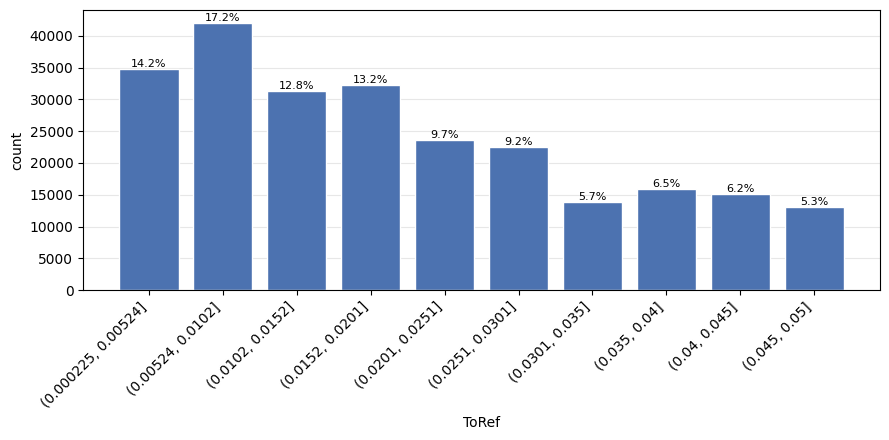

In [25]:
# QcutAnalyzer.plot_cut_distribution(signal_df_model, 'RemainSeconds', bins=10, annot='pct')
QcutAnalyzer.plot_cut_distribution(signal_df_model, 'ToRef', bins=10, annot='pct')

In [26]:
signal_df.Date

0         2025-09-19
1         2025-09-19
2         2025-09-19
3         2025-09-19
4         2025-09-19
             ...    
6589497   2026-09-02
6589498   2026-09-02
6589499   2026-09-02
6589500   2026-09-02
6589501   2026-09-02
Name: Date, Length: 6589502, dtype: datetime64[us]


d = '2026-08-18'
qc = '5425'
ch = 46356#375274
# signal_df# = pd.read_parquet(f'./data/tickFeature/{d}_tickFeature.parquet')#.tail()
signal_df_model[ lambda x : (x.Date == d) & (x.QuoteCode.astype(str) == qc) & (x.ChannelSeq >= ch)].head()

# test = pd.read_parquet(f'./data/tickFeature/{d}_tickFeature.parquet')#.tail()\

In [ ]:
signal_df_model['PosLots'] = signal_df_model.groupby(['Date', 'QuoteCode']).BidPrice1.transform('cumcount') + 1
signal_df_model['Position'] = signal_df_model.groupby(['Date', 'QuoteCode']).BidPrice1.transform('cumsum') / 10
signal_df_model['accLots'] = signal_df_model.groupby(['Date', 'QuoteCode']).BidPrice1.transform('cumcount') + 1

單檔最大 ：600


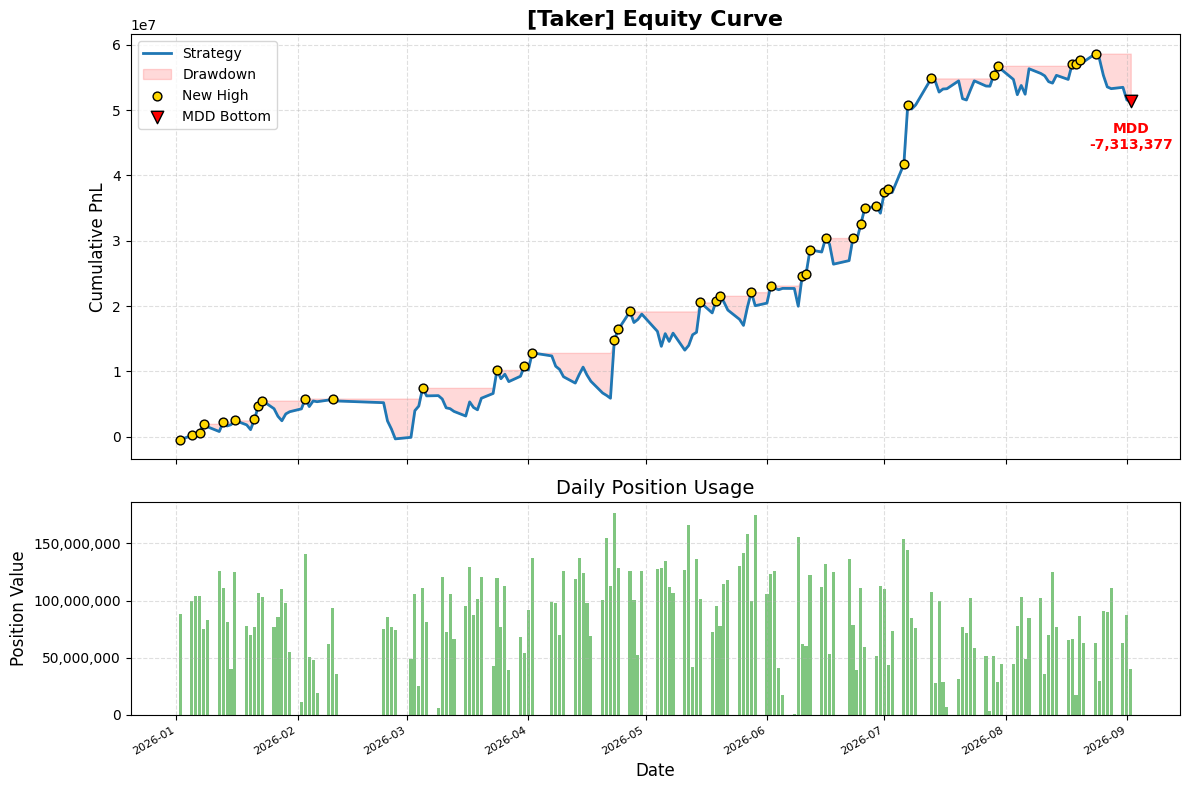


  回測模式: Taker
指標                 | 數值           

------------------ 基礎回報 ------------------
總報酬 (萬)           : 5,134.31
近一年報酬（萬）      : 5,134.31
風報比                  : 7.02
年化 Sharpe          : 2.69
創高最長費時 (天)     : 12
平均每日交易商品數   : 35.77

------------------ 勝率與效率 ------------------
年報酬率（基於平均部位）: 87.92%
近一年報酬率（近一年平均部位）: 58.98%
勝率 (日/單筆)      : 49.07% / 56.41%
平均BP (單筆/單位) : 40.14 / 36.6342

------------------ 風控與部位 ------------------
單日最大虧損（萬） : -306.21 萬
MDD金額/佔平均比   : -731.34 萬 / 8.40%
平均/最大部位(萬)  : 8,705.03 / 17,700.17
平均最大單一商品比  : 9.76%



In [ ]:

r1_mask = (
    (signal_df_model['d_intraday_return'] > 0.04)
    & (signal_df_model['d_intraday_return'] <= 0.08)
    & (signal_df_model['dt_major_count'] <= 0 )
) | (signal_df_model.MarketCap >= 5*(10**11) )

for posLimit in [ 600 ]:
      signalwithRisk_df = signal_df_model[  
      (signal_df_model.accLots < signal_df_model.avg_askLots1 + signal_df_model.avg_bidLots1) &
      (signal_df_model.Position < posLimit)
      & (signal_df_model.BidPrice1<=2000) 
      & ~ r1_mask
      & (signal_df_model.RemainSeconds >= 3600 + 60 * 25) 
      & ( (signal_df_model.hft_strick_makerSpreadBP > -70) | (signal_df_model.hft_strick_makerSpreadBP.isna()))
      & ((signal_df_model.OTC ==1) | (signal_df_model.MD_L1Rate_30_re > 0.25))
            ].reset_index(drop=True)
      signalwithRisk_df['Date'] = signalwithRisk_df.Date.dt.strftime('%Y%m%d')
      
      print ("單檔最大 ：{}".format(posLimit))
      bt = BackTest(signalwithRisk_df[(signalwithRisk_df.Date.astype(int) > 20260101 ) & (signalwithRisk_df.Date.astype(int) < 20260831 ) ])
      results = bt.run_analysis()
      daily_ticker_df = bt.get_daily_ticker_result()


for d in signalwithRisk_df.Date.astype(int).unique():
    if d  >= 20260830:       
        signalwithRisk_df[signalwithRisk_df.Date == str(d) ].to_csv(f'{d}_200w.csv', index=False)

In [ ]:
signalwithRisk_df[ signalwithRisk_df.Date.astype(int) == signalwithRisk_df.Date.astype(int).max() ].QuoteCode.unique()

<ArrowStringArray>
['1303', '2489', '2609', '3037', '3141', '3363', '4908', '4971', '6173',
 '6197', '6217', '6257', '6505', '6526', '6727', '6789', '8111']
Length: 17, dtype: str

In [29]:
signalwithRisk_df[ (signalwithRisk_df.Date.astype(int) == signalwithRisk_df.Date.astype(int).max() ) & (signalwithRisk_df.FutureHigh >= signalwithRisk_df.RefPrice *1.08) ].QuoteCode.unique()

<ArrowStringArray>
['3141', '4971', '6217']
Length: 3, dtype: str

In [30]:
# 計算所有天數的排名比例
series1 = ( signalwithRisk_df.BidPrice1 * (signalwithRisk_df.TakerSell_CloseBP - 19.3) / 10000 / 10).groupby(signalwithRisk_df.Date).sum()
position = (signalwithRisk_df.BidPrice1 / 10).groupby(signalwithRisk_df.Date).sum()

rank_series = series1.rank(pct=True)

dateSeq = -1

# 取得最後一天的排名
latest_date = series1.index[dateSeq]
latest_rank = rank_series.iloc[dateSeq]

print(f"日期: {latest_date}")
print(f"單邊部位: {position.iloc[dateSeq]:.2f} 萬")
print(f"損益: {series1.iloc[dateSeq]:.2f} 萬")
print(f"損益: {series1.iloc[dateSeq]/position.iloc[dateSeq]*100 :.2f} % ")

rank_series = series1.rank()
latest_rank2 = rank_series.iloc[dateSeq]
print(f"排名: {latest_rank2},  {latest_rank :.2%}") # 例如 85.00%，代表贏過歷史 85% 的天數



日期: 20260902
單邊部位: 3972.18 萬
損益: -21.21 萬
損益: -0.53 % 
排名: 82.0,  35.96%


daily_ticker_df.groupby('Date').agg({'損益金額': 'sum', '損益率':'mean'}).reset_index(drop=False).to_csv('portfolios.csv')

In [31]:
# 1. 排序
signalwithRisk_df = signalwithRisk_df.sort_values(['Date', 'TransTime']).reset_index(drop=True)

# 2. 每筆成交的 TXF 等效暴險（元）= 個股名目 × beta（beta 缺值視為 1）
signalwithRisk_df['beta_exposure'] = (
    signalwithRisk_df['BidPrice1'] * 1000 * (signalwithRisk_df['MarketCap'] > 70000000000) * ((signalwithRisk_df['txf_corr_60d'])>0.3)
    * signalwithRisk_df['txf_beta_60d'].fillna(1)
)

# 3. 當日累計 TXF 等效暴險
signalwithRisk_df['cum_beta_exposure'] = (
    signalwithRisk_df.groupby('Date')['beta_exposure'].cumsum()
)

# 4. 一口 TXF 合約價值（元）= 即時中價 × 200
signalwithRisk_df['txf_contract_value'] = signalwithRisk_df['txf_close_mid'] * 200

# 5. 應持避險口數
signalwithRisk_df['hedge_lots'] = (
    signalwithRisk_df['cum_beta_exposure'] // signalwithRisk_df['txf_contract_value']
)

# 6. 新增口數
signalwithRisk_df['delta_lots'] = (
    signalwithRisk_df.groupby('Date')['hedge_lots'].diff()
    .fillna(signalwithRisk_df['hedge_lots'])
)

# 7. 每口避險損益（大台一點 200 元）
signalwithRisk_df['hedge_PL'] = (
    signalwithRisk_df['delta_lots']
    * (signalwithRisk_df['txf_CloseMean'] - (signalwithRisk_df['txf_BidPrice2'] + 4)) / 100 * 200
).fillna(0)

daily_ticker_df = pd.merge(
    daily_ticker_df,
    signalwithRisk_df[['Date','QuoteCode','turnover_rate_rank', 'OTC']].assign(Date=lambda d: pd.to_datetime(d['Date'])),
    on=['Date','QuoteCode'],
    how='inner'
)

daily_ticker_df.to_csv('TradeRecord.csv',index=False)

daily_ticker_df.to_csv('daily_shortPL.csv', index=False)

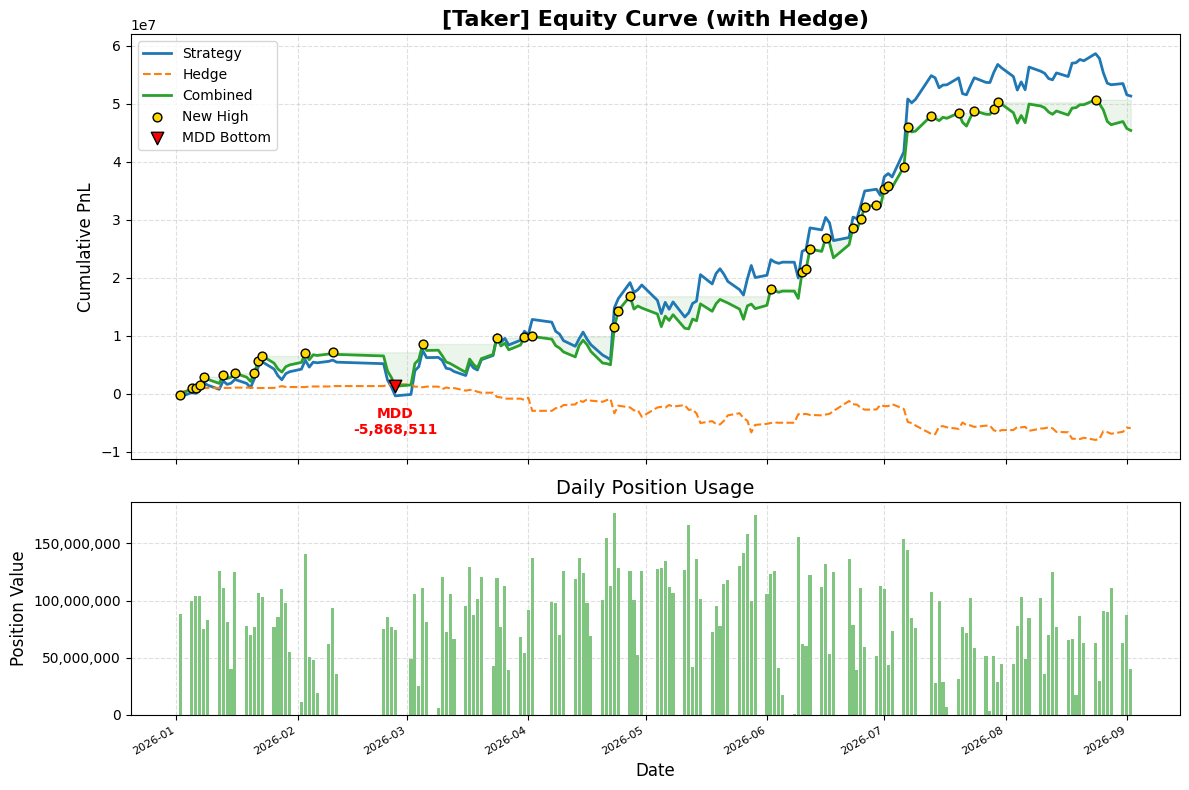


  回測模式: Taker
指標                 | 數值           

------------------ 基礎回報 ------------------
總報酬 (萬)           : 5,134.31
近一年報酬（萬）      : 5,134.31
風報比                  : 7.02
年化 Sharpe          : 2.69
創高最長費時 (天)     : 12
平均每日交易商品數   : 35.77

------------------ 勝率與效率 ------------------
年報酬率（基於平均部位）: 87.92%
近一年報酬率（近一年平均部位）: 58.98%
勝率 (日/單筆)      : 49.07% / 56.41%
平均BP (單筆/單位) : 40.14 / 36.6342

------------------ 風控與部位 ------------------
單日最大虧損（萬） : -306.21 萬
MDD金額/佔平均比   : -731.34 萬 / 8.40%
平均/最大部位(萬)  : 8,705.03 / 17,700.17
平均最大單一商品比  : 9.76%


------------------ 避險統計 ------------------
  原始損益（萬）: 5,134.31
  避險損益（萬）: -593.25
  合併損益（萬）: 4,541.06
  原始 MDD（萬）: -731.34
  合併 MDD（萬）: -586.85
  原始風報比    : 7.02
  合併風報比    : 7.74


In [32]:
bt = BackTest(signalwithRisk_df[ (signalwithRisk_df.Date.astype(int) > 20260101 )])
results = bt.run_analysis()
daily_ticker_df = bt.get_daily_ticker_result()


from pathlib import Path
import os
PROJECT_ROOT = Path(os.path.abspath('')).parents[2]

date_portfolio = series1.reset_index().rename(columns={0: 'PL'})
date_portfolio['Position'] = ( signalwithRisk_df.BidPrice1 / 10).groupby(signalwithRisk_df.Date).sum().reset_index(drop=True)
date_portfolio['Return'] = date_portfolio['PL'] / date_portfolio['Position'] * 100

dateData = []
for d in tqdm( date_portfolio.Date[:-1] ) : 
    # 讀取 marketData
    maket_df = pd.read_parquet(f'/media/kevin/SSD2/Data/marketData/{d}_marketData.parquet')
    
    # 讀取 preMarketData (對應日期的每日特徵)
    premarket_df = pd.read_parquet(f'/media/kevin/SSD2/Data/preMarket/{d}_preMarketData.parquet')
    
    # 確保 key 都是字串型態以防合併錯誤
    maket_df['quote_code'] = maket_df['quote_code'].astype(str)
    premarket_df['QuoteCode'] = premarket_df['QuoteCode'].astype(str)
    
    # 合併兩個 DataFrame
    merged_df = pd.merge(
        maket_df, 
        premarket_df, 
        left_on='quote_code', 
        right_on='QuoteCode', 
        how='inner'
    )
    
    # 計算 toOpen
    merged_df['toOpen'] = (merged_df['open_price'] - merged_df['opening_ref_price']) / merged_df['opening_ref_price']
    merged_df['Return'] = (merged_df['close_price'] - merged_df['opening_ref_price']) / merged_df['opening_ref_price']

    tsmc = merged_df[merged_df['quote_code'] == '2330']
    tsmcOpen = tsmc.toOpen.iloc[0]
    tsmcReturn = tsmc.Return.iloc[0]
    # 2. day_amount_rank < 100 的 mean
    top_df = merged_df[merged_df['day_amount_rank'] < 100]
    topOpen = top_df.toOpen.mean(numeric_only=True)
    topLimit = (top_df.high_price > top_df.opening_ref_price*1.08).mean()
    topDrop = top_df.toOpen.apply(np.sign).mean(numeric_only=True)
    topReturn = top_df.Return.mean(numeric_only=True)
    
    dateData.append( [tsmcOpen, tsmcReturn, topOpen, topLimit, topDrop, topReturn])
    # break


date_portfolio = pd.concat( [date_portfolio, pd.DataFrame(columns=['tsmOpen', 'tsmReturn', 'topOpen', 'topLimit', 'topDrop', 'topReturn'], data = dateData) ], axis = 1)

date_portfolio['topLimit_last'] = date_portfolio['topLimit'].shift()
date_portfolio['topLimit_last5'] = date_portfolio['topLimit'].rolling(window=5).mean().shift()
date_portfolio['Return_last'] = date_portfolio['Return'].shift()
date_portfolio['Return_last5'] = date_portfolio['Return'].rolling(window=5).mean().shift()

QcutAnalyzer.plot_qcut_analysis(date_portfolio, col_a='Return_last5', col_b=f'Return', q=20 , isMin=False)

from pathlib import Path
import matplotlib.pyplot as plt

from src.research.negFill.strategy_benchmark_analysis import (
    analyze_strategy_vs_benchmarks,
)

daily_compare, alpha_summary, fig = analyze_strategy_vs_benchmarks(
    signalwithRisk_df,
    project_root=Path("/home/kevin/Project/HFT"),
    rolling_days=20,
    top_stop_ratio=1.085,
)

display(alpha_summary)
plt.show()